In [23]:
from load_basics import *
from nbodykit.source.catalog import BigFileCatalog
from nbodykit.lab import ArrayCatalog, FFTPower
import h5py, glob
# from astrid_utils import *
from astropy.cosmology import Planck15 as cosmo
from astropy import units


### functions

In [24]:
def gen_mesh_g4(flist, snap, Lbox = 400, Nmesh = 128, comp = False):
    asnap = alist[snap]
    sdir = flist[snap]
    
    hf = h5py.File(sdir)
    pos = hf["PartType1/Coordinates"][:]
    vel = hf["PartType1/Velocities"][:]
    cat = ArrayCatalog({'Position' : pos, 'Velocity' : vel}, BoxSize=[Lbox, Lbox, Lbox])
    cat["Vx"] = vel[:, 0] * np.sqrt(asnap) # to peculiar velocity in km/s
    cat["Vy"] = vel[:, 1] * np.sqrt(asnap)
    cat["Vz"] = vel[:, 2] * np.sqrt(asnap)
    mesh_rho = cat.to_mesh(compensated=comp, resampler='tsc',Nmesh=Nmesh,position='Position')
    mesh_vx = cat.to_mesh(compensated=comp, resampler='tsc', position='Position', value='Vx', Nmesh=Nmesh)
    mesh_vy = cat.to_mesh(compensated=comp, resampler='tsc', position='Position', value='Vy', Nmesh=Nmesh)
    mesh_vz = cat.to_mesh(compensated=comp, resampler='tsc', position='Position', value='Vz', Nmesh=Nmesh)
    return mesh_rho, mesh_vx, mesh_vy, mesh_vz

def downsize(one_plus_delta, factor):
    """
    Downsize the mesh by a factor of `factor`.
    """
    if factor == 1:
        return one_plus_delta
    elif factor < 1:
        raise ValueError("Downsize factor must be >= 1")
    
    new_shape = (one_plus_delta.shape[0] // factor, 
                 one_plus_delta.shape[1] // factor, 
                 one_plus_delta.shape[2] // factor)
    
    downsampled = one_plus_delta.reshape(new_shape[0], factor, \
        new_shape[1], factor, new_shape[2], factor).mean(axis=(1,3,5))
    return downsampled

def plot_density(ax, one_plus_delta, label):
    ax.imshow(one_plus_delta[:,:,30],vmax=5,vmin=0.005)
    ax.set_title(label)
    ax.set_xlabel('x [Mpc/h]')
    ax.set_ylabel('y [Mpc/h]')

def compute_power(mesh):
    rr = FFTPower(mesh,mode='1d')
    Pk = rr.power
    ps = Pk['power'].real - Pk.attrs['shotnoise']
    k0, Pk = Pk['k'], ps * Pk['k'] * Pk['k'] * Pk['k'] / (2 * np.pi * np.pi)
    return k0, Pk


In [25]:
def compute_power(mesh):
    rr = FFTPower(mesh,mode='1d')
    Pk = rr.power
    ps = Pk['power'].real - Pk.attrs['shotnoise']
    k0, Pk = Pk['k'], ps * Pk['k'] * Pk['k'] * Pk['k'] / (2 * np.pi * np.pi)
    return k0, Pk, ps

def compute_cross(mesh1, mesh2):
    k0_1, Pk_1, ps1 = compute_power(mesh1)
    k0_2, Pk_2, ps2 = compute_power(mesh2)
    
    rr = FFTPower(mesh1,second = mesh2, mode='1d')
    Pk = rr.power
    ps = Pk['power'].real - Pk.attrs['shotnoise']

    eta = ps / np.sqrt(ps1 * ps2)
    return k0_1, ps1, ps2, eta

### prepare mesh

In [26]:
oroot = "/home/nianyic/scratch1/FMsims/gadget4/test_vel128/output"
Nmesh = 128
Lbox = 400

In [27]:
snapfiles = sorted(glob.glob(oroot + "/snap_*.hdf5"))
snaplist = np.arange(len(snapfiles))
zlist = []
alist = []
tlist = []
for sf in snapfiles:
    hf = h5py.File(sf, "r")
    zz = hf["Header"].attrs["Redshift"]
    zlist.append(zz)
    alist.append(hf["Header"].attrs["Time"])
    time = cosmo.age(zz)
    tlist.append(time)

for i in range(len(snaplist)):
    print(snaplist[i], zlist[i], tlist[i])

0 2.4529638238286116 2.6710511957600485 Gyr
1 2.3307873856773873 2.816690548651072 Gyr
2 2.2245291388155515 2.954266954785189 Gyr
3 2.1216607255632405 3.0982624843518147 Gyr
4 2.0329804208388276 3.2318541064262756 Gyr
5 1.936222764174691 3.388675751767532 Gyr
6 1.8528103909678664 3.5340821708134933 Gyr
7 1.7817706825167638 3.66610471335125 Gyr
8 1.702745992300144 3.8226315665005375 Gyr
9 0.4916289367677069 8.665421039749411 Gyr
10 0.47028915214117695 8.825196546467405 Gyr
11 0.4492546622140734 8.98701241609409 Gyr
12 0.4285210993296875 9.15085744203447 Gyr
13 0.40808415831659084 9.316719098734437 Gyr
14 0.3879395955946996 9.484583558451899 Gyr
15 0.11012233272674266 12.328180962022623 Gyr
16 0.09818954411720071 12.476450536244196 Gyr
17 0.08638502195163755 12.625616928200367 Gyr
18 0.07470738748438022 12.775667212471527 Gyr
19 0.06315527678999922 12.926588331833752 Gyr
20 0.05172734060399953 13.078367111487774 Gyr
21 0.04042224416523399 13.230990273194744 Gyr
22 0.029238667060002443 13

In [88]:
def delta_dot_finite_difference(snap1, snap2, Nmesh):
    """
    Compute the finite difference of delta at two snapshots.
    """
    mesh_rho1, mesh_vx1, mesh_vy1, mesh_vz1 = gen_mesh_g4(snapfiles, snap=snap1, Lbox=Lbox, Nmesh=Nmesh, comp=False)
    mesh_rho2, mesh_vx2, mesh_vy2, mesh_vz2 = gen_mesh_g4(snapfiles, snap=snap2, Lbox=Lbox, Nmesh=Nmesh, comp=False)

    delta_1 = mesh_rho1.paint(mode='real').value - 1
    delta_2 = mesh_rho2.paint(mode='real').value - 1

    delta_dot = (delta_2 - delta_1) / (tlist[snap2] - tlist[snap1])

    return delta_dot

### compute delta_dot: finite differencing

In [108]:
# convergence around z=0.02
snap_pairs = [(17, 28), (18, 27), (19, 26), (20, 25), (21, 24), (22, 23)]
snap_pairs = [(9, 14), (10, 13), (11, 12)]
delta_list = []
dt_list = []

for snap1, snap2 in snap_pairs:
    delta_dot = delta_dot_finite_difference(snap1, snap2, Nmesh)
    delta_list.append(delta_dot)
    dt_list.append(tlist[snap2] - tlist[snap1])


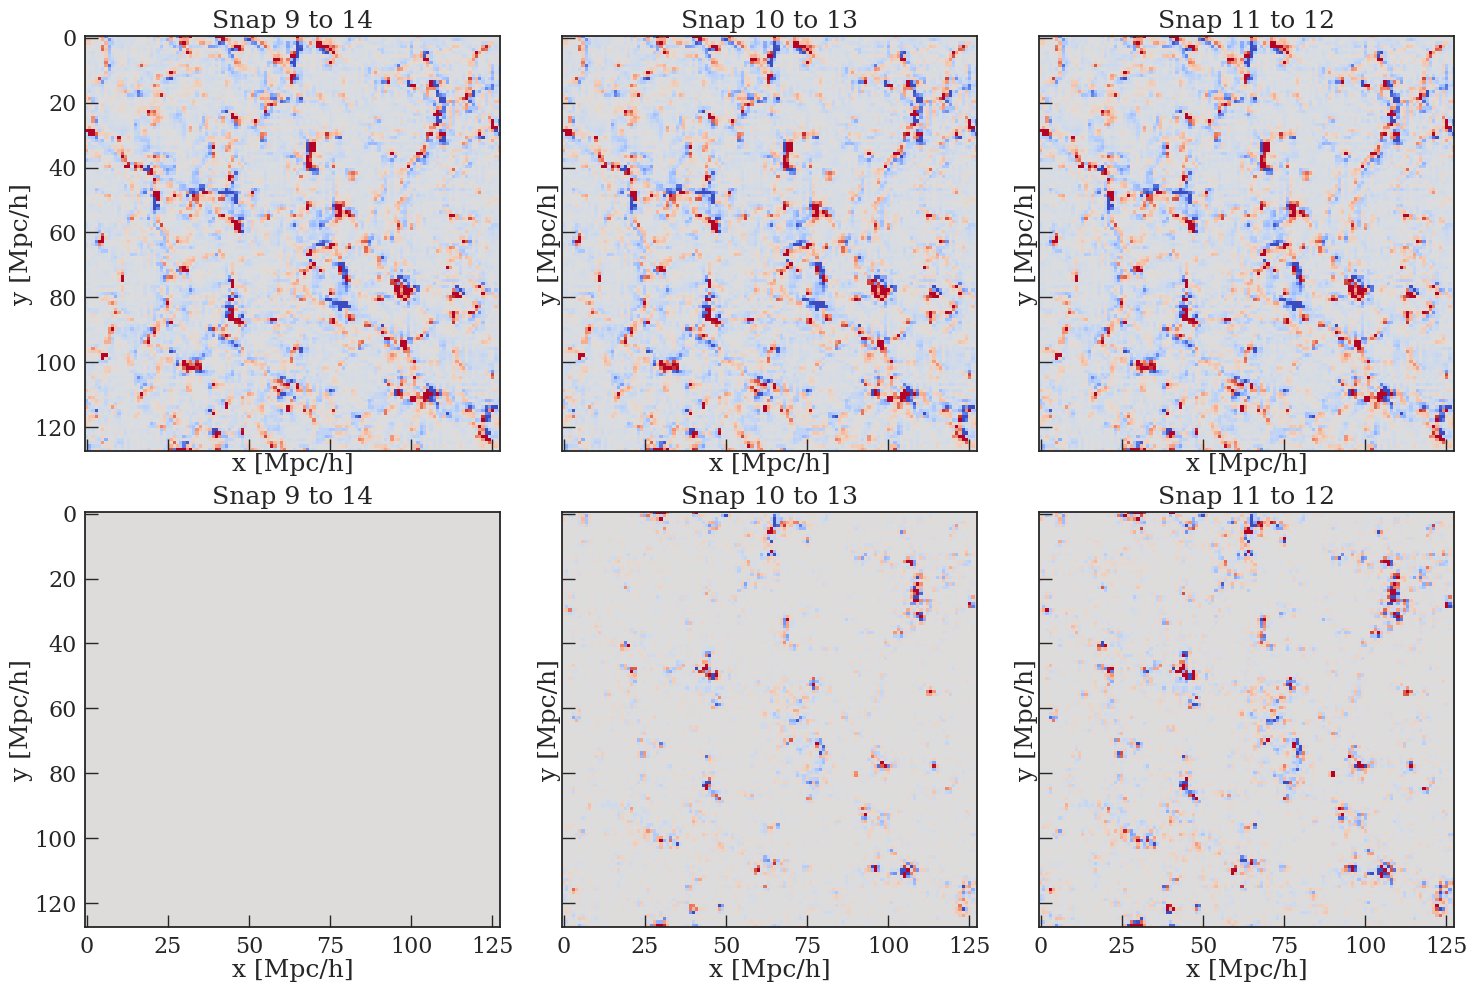

In [113]:
from matplotlib.colors import LogNorm
rho0 = mesh_rho0.paint(mode='real').value
rho2 = mesh_rho2.paint(mode='real').value

delta_dot_fd = (rho2 - rho0) / (t2 - t0) # in unit of Gyr^-1

fig, ax = plt.subplots(figsize=(15,10),ncols=3,nrows=2, sharex=True, sharey=True)
ax = ax.flatten()
for i, delta_dot in enumerate(delta_list):
    ax[i].imshow(delta_dot[:,:,30], vmin=-0.5, vmax=0.5, cmap='coolwarm')
    ax[i].set_title(f"Snap {snap_pairs[i][0]} to {snap_pairs[i][1]}")
    ax[i].set_xlabel('x [Mpc/h]')
    ax[i].set_ylabel('y [Mpc/h]')

for i, delta_dot in enumerate(delta_list):
    ax[i+3].imshow(delta_dot[:,:,30] - delta_list[0][:,:,30], vmin=-1e-2, vmax=1e-2, cmap='coolwarm')
    ax[i+3].set_title(f"Snap {snap_pairs[i][0]} to {snap_pairs[i][1]}")
    ax[i+3].set_xlabel('x [Mpc/h]')
    ax[i+3].set_ylabel('y [Mpc/h]')


fig.tight_layout()
plt.show()

In [114]:
from nbodykit.lab import *
mesh23, _, _, _ = gen_mesh_g4(snapfiles, snap=12, Lbox=Lbox, Nmesh=Nmesh, comp=False)
delta23 = mesh23.paint(mode='real').value - 1
delta23 = downsize(delta23, factor=1)
mesh_d23 = ArrayMesh(delta23, BoxSize=400.0)
mesh_delta_dot_23 = ArrayMesh(delta_list[-1], BoxSize=400.0)

cross_rho = []
cross_delta = []
power = []
klist = []
p_delta_23 = None
for delta_dot in delta_list:
    delta_dot = downsize(delta_dot, factor=1)
    mesh_delta_dot = ArrayMesh(delta_dot, BoxSize=400.0)
    k0, ps1, ps2, eta = compute_cross(mesh_d23, mesh_delta_dot)
    p_delta_23 = ps1
    cross_rho.append(eta)
    power.append(ps2)
    k0_1, ps1, ps2, eta = compute_cross(mesh_delta_dot_23, mesh_delta_dot)
    cross_delta.append(eta)
    klist.append(k0_1)

/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in true_divide
  


In [115]:
### linear theory

zz = 0.4285210993296875  # redshift for linear power spectrum
aa = 1 / (1 + zz)
from colossus.cosmology import cosmology
cosmo_col = cosmology.setCosmology('planck15')
D_of_a = cosmo_col.growthFactor(zz)
dD_dz = cosmo_col.growthFactor(zz, derivative=1)
f_a = - dD_dz / D_of_a / aa


from nbodykit.lab import LinearMesh
from nbodykit.lab import cosmology as cosmo_nbodykit

#cosmo1 = cosmo_nbodykit.Planck15
#Plin = cosmo_nbodykit.LinearPower(cosmo1, redshift=zz, transfer='CLASS')
# make H in unit of Gyr^-1
P_rho = p_delta_23
Ha = cosmo.H(zz)  # in unit of km/s/Mpc
Ha = Ha.to(units.Gyr**-1).value  # convert to Gyr^-1
#p_deltadot = f_a**2 * Ha**2 * Plin(k=klist[-1])
p_deltadot = f_a**2 * Ha**2 * P_rho
# mesh_lin = LinearMesh(Plin, Nmesh=128, BoxSize=400, seed=42)


[None, None]

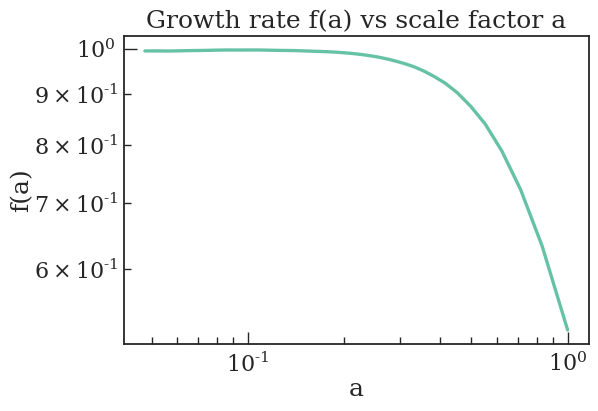

In [132]:
zzlist = np.linspace(0,20,100)
aalist = 1 / (1 + zzlist)

from colossus.cosmology import cosmology
cosmo_col = cosmology.setCosmology('planck15')
D_of_a = cosmo_col.growthFactor(zzlist)
dD_dz = cosmo_col.growthFactor(zzlist, derivative=1)
f_a = - dD_dz / D_of_a / aalist

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot(aalist, f_a)
ax.set_xlabel('a')
ax.set_ylabel('f(a)')
ax.set_title('Growth rate f(a) vs scale factor a')
ax.set(xscale='log', yscale='log' )

/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:7: RuntimeWarning: invalid value encountered in true_divide
  import sys


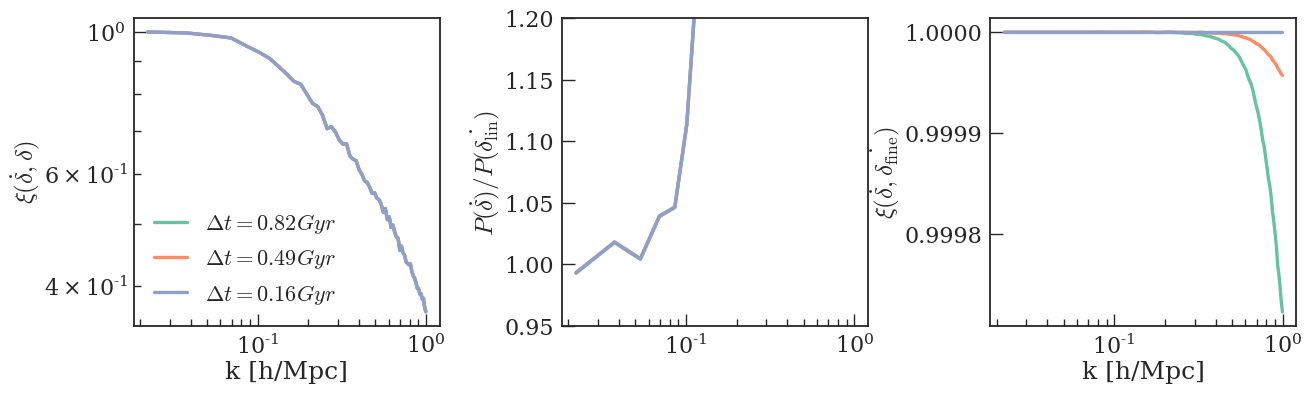

In [116]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
plt.subplots_adjust(wspace=0.4)
for i, (k0, eta) in enumerate(zip(klist, cross_rho)):
    # if i == len(cross_rho) - 1:
    #     break
    ax[0].plot(k0, eta, label=f'$\Delta t={dt_list[i]:.2f}$')
    ax[1].plot(k0, power[i]/p_deltadot, label=f'$\Delta t={dt_list[i]:.2f}$')
    ax[2].plot(k0, cross_delta[i], label=f'$\Delta t={dt_list[i]:.2f}$')
ax[0].legend()
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_xlabel('k [h/Mpc]')
ax[0].set_ylabel(r'$\xi(\dot{\delta}, \delta)$')
ax[1].set_ylabel(r'$P(\dot{\delta}) / P(\dot{\delta_{\rm lin}})$')
# ax[1].set_yscale('log')
ax[2].set_ylabel(r'$\xi(\dot{\delta}, \dot{\delta_{\rm fine}})$')
# ax[2].set_yscale('log')
ax[2].set_xlabel('k [h/Mpc]')

ax[1].set(ylim=[0.95,1.2])
plt.show()


#### z=2

In [123]:
# convergence around z=0.02
snap_pairs = [(17, 28), (18, 27), (19, 26), (20, 25), (21, 24), (22, 23)]
snap_pairs = [(0, 8), (1, 7), (2, 6), (3, 5)]
delta_list = []
dt_list = []

for snap1, snap2 in snap_pairs:
    delta_dot = delta_dot_finite_difference(snap1, snap2, Nmesh)
    delta_list.append(delta_dot)
    dt_list.append(tlist[snap2] - tlist[snap1])


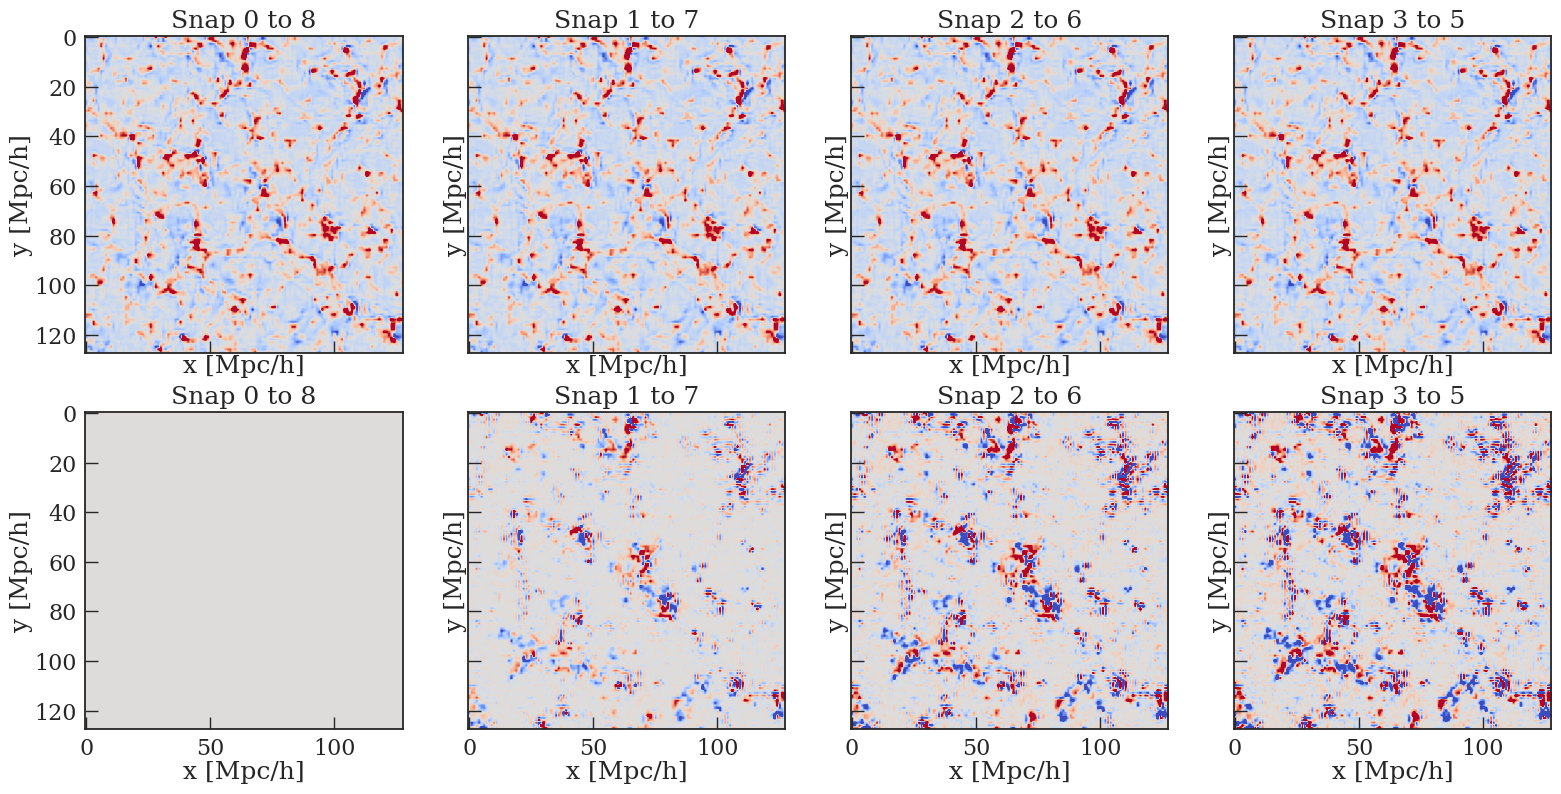

In [124]:
from matplotlib.colors import LogNorm
rho0 = mesh_rho0.paint(mode='real').value
rho2 = mesh_rho2.paint(mode='real').value

delta_dot_fd = (rho2 - rho0) / (t2 - t0) # in unit of Gyr^-1

fig, ax = plt.subplots(figsize=(16,8),ncols=4,nrows=2, sharex=True, sharey=True)
ax = ax.flatten()
for i, delta_dot in enumerate(delta_list):
    ax[i].imshow(delta_dot[:,:,30], vmin=-0.5, vmax=0.5, cmap='coolwarm')
    ax[i].set_title(f"Snap {snap_pairs[i][0]} to {snap_pairs[i][1]}")
    ax[i].set_xlabel('x [Mpc/h]')
    ax[i].set_ylabel('y [Mpc/h]')

for i, delta_dot in enumerate(delta_list):
    ax[i+4].imshow(delta_dot[:,:,30] - delta_list[0][:,:,30], vmin=-1e-2, vmax=1e-2, cmap='coolwarm')
    ax[i+4].set_title(f"Snap {snap_pairs[i][0]} to {snap_pairs[i][1]}")
    ax[i+4].set_xlabel('x [Mpc/h]')
    ax[i+4].set_ylabel('y [Mpc/h]')
fig.tight_layout()
plt.show()

In [120]:
from nbodykit.lab import *
mesh23, _, _, _ = gen_mesh_g4(snapfiles, snap=4, Lbox=Lbox, Nmesh=Nmesh, comp=False)
delta23 = mesh23.paint(mode='real').value - 1
delta23 = downsize(delta23, factor=1)
mesh_d23 = ArrayMesh(delta23, BoxSize=400.0)
mesh_delta_dot_23 = ArrayMesh(delta_list[-1], BoxSize=400.0)

cross_rho = []
cross_delta = []
power = []
klist = []
p_delta_23 = None
for delta_dot in delta_list:
    delta_dot = downsize(delta_dot, factor=1)
    mesh_delta_dot = ArrayMesh(delta_dot, BoxSize=400.0)
    k0, ps1, ps2, eta = compute_cross(mesh_d23, mesh_delta_dot)
    p_delta_23 = ps1
    cross_rho.append(eta)
    power.append(ps2)
    k0_1, ps1, ps2, eta = compute_cross(mesh_delta_dot_23, mesh_delta_dot)
    cross_delta.append(eta)
    klist.append(k0_1)

/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in true_divide
  


In [121]:
### linear theory

zz = 2.0329804208388276  # redshift for linear power spectrum
aa = 1 / (1 + zz)
from colossus.cosmology import cosmology
cosmo_col = cosmology.setCosmology('planck15')
D_of_a = cosmo_col.growthFactor(zz)
dD_dz = cosmo_col.growthFactor(zz, derivative=1)
f_a = - dD_dz / D_of_a / aa


from nbodykit.lab import LinearMesh
from nbodykit.lab import cosmology as cosmo_nbodykit

#cosmo1 = cosmo_nbodykit.Planck15
#Plin = cosmo_nbodykit.LinearPower(cosmo1, redshift=zz, transfer='CLASS')
# make H in unit of Gyr^-1
P_rho = p_delta_23
Ha = cosmo.H(zz)  # in unit of km/s/Mpc
Ha = Ha.to(units.Gyr**-1).value  # convert to Gyr^-1
#p_deltadot = f_a**2 * Ha**2 * Plin(k=klist[-1])
p_deltadot = f_a**2 * Ha**2 * P_rho
# mesh_lin = LinearMesh(Plin, Nmesh=128, BoxSize=400, seed=42)


/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:7: RuntimeWarning: invalid value encountered in true_divide
  import sys


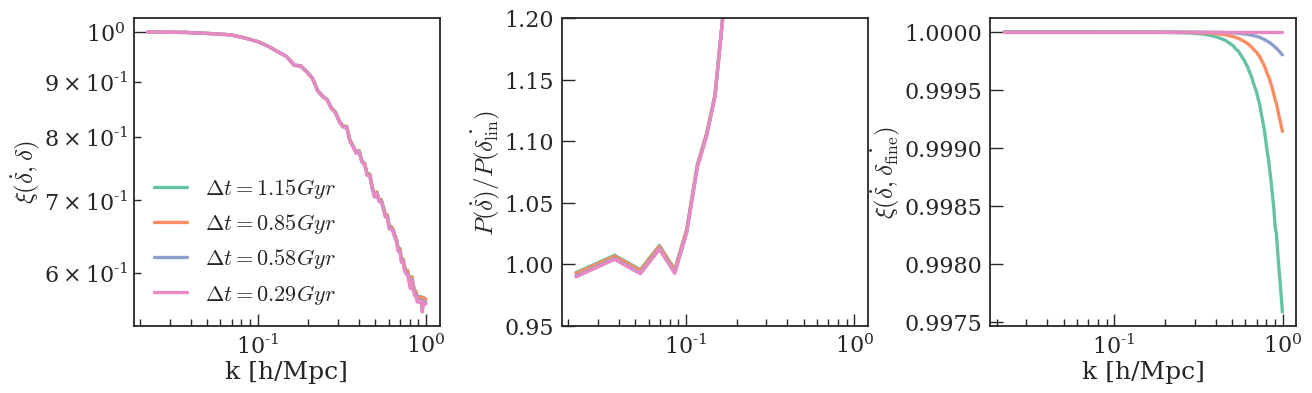

In [122]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
plt.subplots_adjust(wspace=0.4)
for i, (k0, eta) in enumerate(zip(klist, cross_rho)):
    # if i == len(cross_rho) - 1:
    #     break
    ax[0].plot(k0, eta, label=f'$\Delta t={dt_list[i]:.2f}$')
    ax[1].plot(k0, power[i]/p_deltadot, label=f'$\Delta t={dt_list[i]:.2f}$')
    ax[2].plot(k0, cross_delta[i], label=f'$\Delta t={dt_list[i]:.2f}$')
ax[0].legend()
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_xlabel('k [h/Mpc]')
ax[0].set_ylabel(r'$\xi(\dot{\delta}, \delta)$')
ax[1].set_ylabel(r'$P(\dot{\delta}) / P(\dot{\delta_{\rm lin}})$')
# ax[1].set_yscale('log')
ax[2].set_ylabel(r'$\xi(\dot{\delta}, \dot{\delta_{\rm fine}})$')
# ax[2].set_yscale('log')
ax[2].set_xlabel('k [h/Mpc]')

ax[1].set(ylim=[0.95,1.2])
plt.show()


### z=0.03

In [125]:
# convergence around z=0.02
snap_pairs = [(17, 28), (18, 27), (19, 26), (20, 25), (21, 24), (22, 23)]
snap_pairs = [(18, 28), (19, 26), (20, 24), (21, 22)]
delta_list = []
dt_list = []

for snap1, snap2 in snap_pairs:
    delta_dot = delta_dot_finite_difference(snap1, snap2, Nmesh)
    delta_list.append(delta_dot)
    dt_list.append(tlist[snap2] - tlist[snap1])


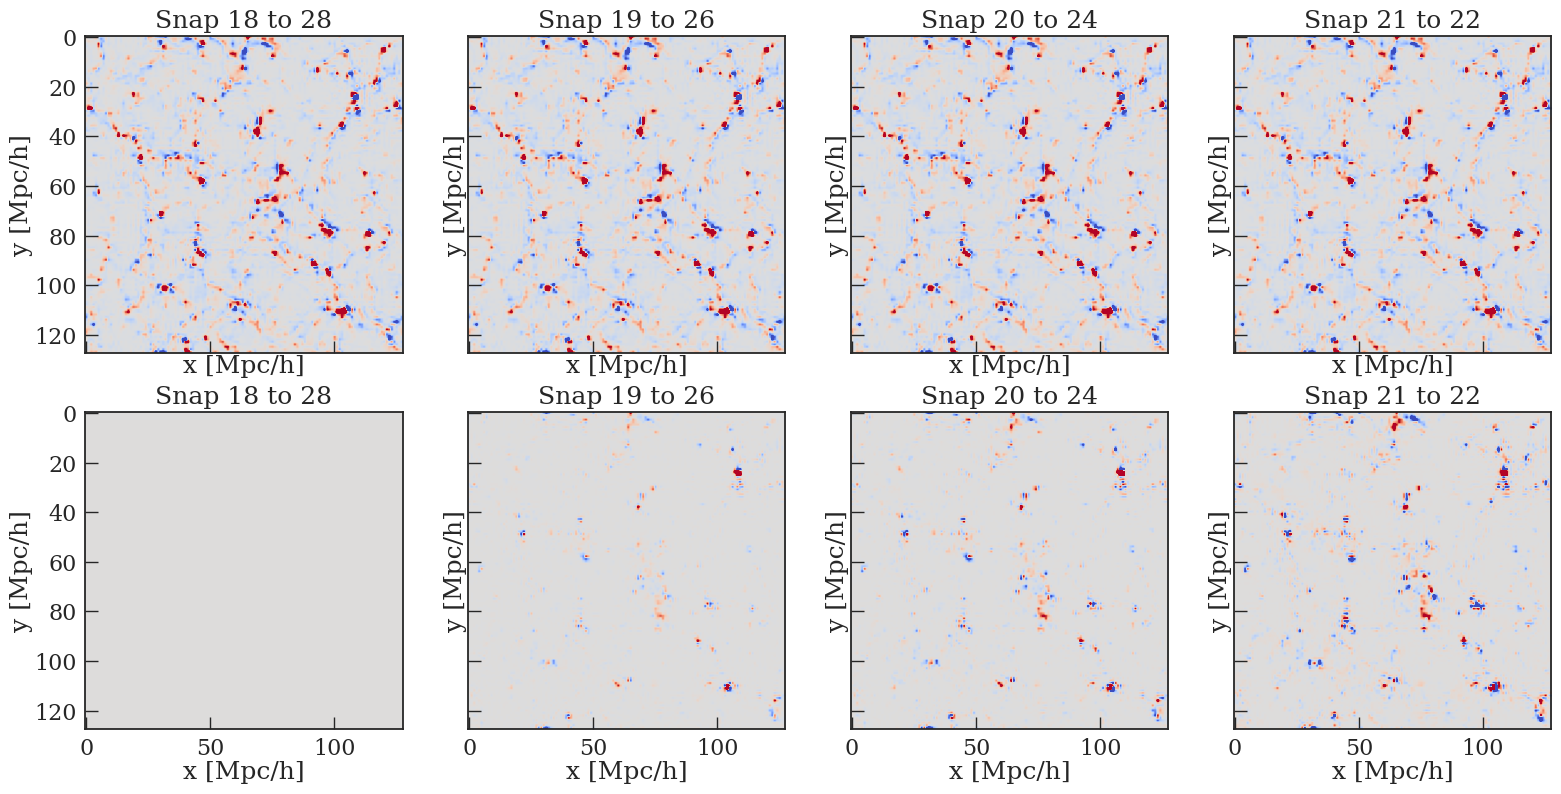

In [126]:
from matplotlib.colors import LogNorm
rho0 = mesh_rho0.paint(mode='real').value
rho2 = mesh_rho2.paint(mode='real').value

delta_dot_fd = (rho2 - rho0) / (t2 - t0) # in unit of Gyr^-1

fig, ax = plt.subplots(figsize=(16,8),ncols=4,nrows=2, sharex=True, sharey=True)
ax = ax.flatten()
for i, delta_dot in enumerate(delta_list):
    ax[i].imshow(delta_dot[:,:,30], vmin=-0.5, vmax=0.5, cmap='coolwarm')
    ax[i].set_title(f"Snap {snap_pairs[i][0]} to {snap_pairs[i][1]}")
    ax[i].set_xlabel('x [Mpc/h]')
    ax[i].set_ylabel('y [Mpc/h]')

for i, delta_dot in enumerate(delta_list):
    ax[i+4].imshow(delta_dot[:,:,30] - delta_list[0][:,:,30], vmin=-1e-2, vmax=1e-2, cmap='coolwarm')
    ax[i+4].set_title(f"Snap {snap_pairs[i][0]} to {snap_pairs[i][1]}")
    ax[i+4].set_xlabel('x [Mpc/h]')
    ax[i+4].set_ylabel('y [Mpc/h]')
fig.tight_layout()
plt.show()

### cross correlate with delta at z=0.02

In [127]:
from nbodykit.lab import *
mesh23, _, _, _ = gen_mesh_g4(snapfiles, snap=22, Lbox=Lbox, Nmesh=Nmesh, comp=False)
delta23 = mesh23.paint(mode='real').value - 1
delta23 = downsize(delta23, factor=1)
mesh_d23 = ArrayMesh(delta23, BoxSize=400.0)
mesh_delta_dot_23 = ArrayMesh(delta_list[-1], BoxSize=400.0)

cross_rho = []
cross_delta = []
power = []
klist = []
p_delta_23 = None
for delta_dot in delta_list:
    delta_dot = downsize(delta_dot, factor=1)
    mesh_delta_dot = ArrayMesh(delta_dot, BoxSize=400.0)
    k0, ps1, ps2, eta = compute_cross(mesh_d23, mesh_delta_dot)
    p_delta_23 = ps1
    cross_rho.append(eta)
    power.append(ps2)
    k0_1, ps1, ps2, eta = compute_cross(mesh_delta_dot_23, mesh_delta_dot)
    cross_delta.append(eta)
    klist.append(k0_1)

/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in true_divide
  


In [128]:
### linear theory

zz = 0.035  # redshift for linear power spectrum
aa = 1 / (1 + zz)
from colossus.cosmology import cosmology
cosmo_col = cosmology.setCosmology('planck15')
D_of_a = cosmo_col.growthFactor(zz)
dD_dz = cosmo_col.growthFactor(zz, derivative=1)
f_a = - dD_dz / D_of_a / aa


from nbodykit.lab import LinearMesh
from nbodykit.lab import cosmology as cosmo_nbodykit

#cosmo1 = cosmo_nbodykit.Planck15
#Plin = cosmo_nbodykit.LinearPower(cosmo1, redshift=zz, transfer='CLASS')
# make H in unit of Gyr^-1
P_rho = p_delta_23
Ha = cosmo.H(zz)  # in unit of km/s/Mpc
Ha = Ha.to(units.Gyr**-1).value  # convert to Gyr^-1
#p_deltadot = f_a**2 * Ha**2 * Plin(k=klist[-1])
p_deltadot = f_a**2 * Ha**2 * P_rho
# mesh_lin = LinearMesh(Plin, Nmesh=128, BoxSize=400, seed=42)


/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:7: RuntimeWarning: invalid value encountered in true_divide
  import sys


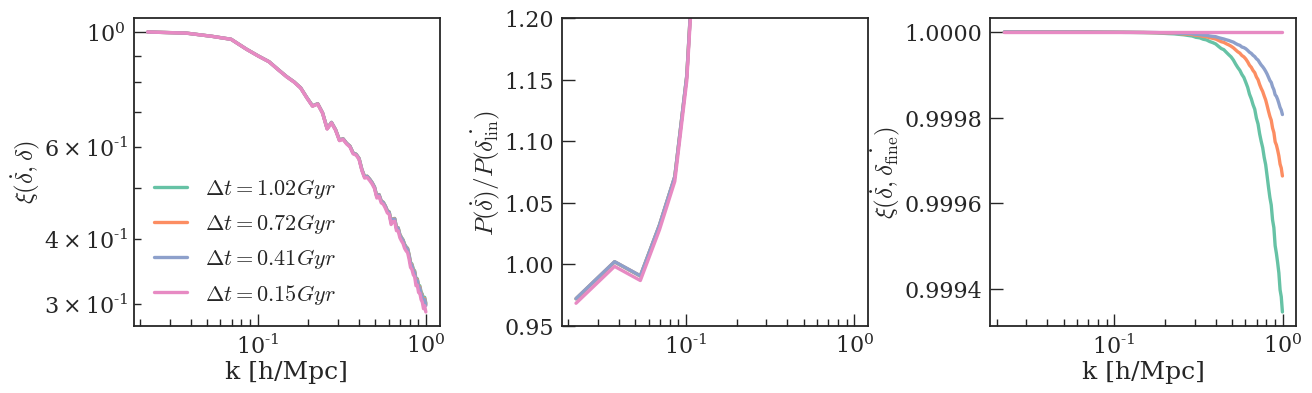

In [129]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
plt.subplots_adjust(wspace=0.4)
for i, (k0, eta) in enumerate(zip(klist, cross_rho)):
    # if i == len(cross_rho) - 1:
    #     break
    ax[0].plot(k0, eta, label=f'$\Delta t={dt_list[i]:.2f}$')
    ax[1].plot(k0, power[i]/p_deltadot, label=f'$\Delta t={dt_list[i]:.2f}$')
    ax[2].plot(k0, cross_delta[i], label=f'$\Delta t={dt_list[i]:.2f}$')
ax[0].legend()
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_xlabel('k [h/Mpc]')
ax[0].set_ylabel(r'$\xi(\dot{\delta}, \delta)$')
ax[1].set_ylabel(r'$P(\dot{\delta}) / P(\dot{\delta_{\rm lin}})$')
# ax[1].set_yscale('log')
ax[2].set_ylabel(r'$\xi(\dot{\delta}, \dot{\delta_{\rm fine}})$')
# ax[2].set_yscale('log')
ax[2].set_xlabel('k [h/Mpc]')

ax[1].set(ylim=[0.95,1.2])
plt.show()
